# 18 — Tracking in-domain (E2b): detector addestrato su SportsMOT

**Richiesta del relatore (6 novembre).** In E1 la detection è valutata *in-domain* (test Roboflow) e *fuori dominio* (SportsMOT). In E2 il tracking è stato valutato solo fuori dominio: detector addestrati su Roboflow, tracking su SportsMOT val (HOTA 0,539).

Il dataset Roboflow v18 contiene immagini singole, senza identità nel tempo: non permette di valutare il tracking. La versione in-domain del tracking si ottiene quindi così:

| | Detector addestrato su | Tracking valutato su |
|---|---|---|
| E2 (notebook 11), fuori dominio | Roboflow v18 | SportsMOT **val** (15 sequenze di basket) |
| **E2b (questo notebook), in-domain** | **SportsMOT train** (sequenze di basket) | SportsMOT **val**, le stesse 15 sequenze |

Il protocollo di tracking è identico al notebook 11: detection calcolate una volta e salvate (confidenza minima 0,05), stessi cinque tracker della libreria `trackers` con **parametri di default**, stessa interpolazione (≤ 20 frame), stessa valutazione (HOTA, MOTA, IDF1, ID switch). Cambia **solo il detector**. SAM2 non viene ripetuto.

**Regole per un confronto onesto**
- SportsMOT val non è mai usato per l'addestramento né per scegliere parametri: la validazione interna dell'addestramento usa **due sequenze del train tenute da parte**.
- Il notebook controlla se train e val contengono clip della **stessa partita** (stesso video YouTube) e lo riporta; con `EXCLUDE_SHARED_VIDEOS = True` le esclude dal train.

Runtime consigliato: **Colab GPU L4** (addestramento circa 1–1,5 h). Su T4 funziona, più lentamente.

In [1]:
%pip install -q ultralytics trackers supervision

In [1]:
# ==== SETUP COMUNE (uguale in tutti i notebook) ====
import sys, os
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Tesi_Basket')   # progetto su Drive
    FAST = Path('/content/fast')                         # disco locale Colab (veloce)
else:
    ROOT = Path(r'F:\Tesi Basket')                       # progetto in locale
    FAST = ROOT / '_cache'
FAST.mkdir(parents=True, exist_ok=True)
assert ROOT.is_dir(), f'Cartella del progetto non trovata: {ROOT}'
print('Progetto:', ROOT)

os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
import json, time, shutil, subprocess, urllib.request, configparser, random
import numpy as np, pandas as pd, cv2, torch
import supervision as sv
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

EXP = ROOT / 'experiments' / 'E2b_tracking_indomain'      # risultati di questo esperimento
EXP_E2 = ROOT / 'experiments' / 'E2_tracking'              # risultati del notebook 11 (fuori dominio), solo lettura
EXP.mkdir(parents=True, exist_ok=True)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NESSUNA')

Mounted at /content/drive
Progetto: /content/drive/MyDrive/Tesi_Basket
GPU: NVIDIA L4


## 1. Configurazione

In [2]:
# --- dati ---
SMOT_VAL = FAST / 'SportsMOT'          # stessa cartella del notebook 11
SMOT_TRAIN = FAST / 'SportsMOT_train'
SMOT_CACHE = FAST / '_cache_sportsmot' # zip scaricati: sul disco di Colab (il train è grande, non lo mettiamo su Drive)
BASKET_LIST = ROOT / 'datasets' / 'sportsmot_basketball.txt'
EXCLUDE_SHARED_VIDEOS = False          # True = togli dal train le clip della stessa partita (stesso video) di una clip di val
N_HOLDOUT_SEQ = 2                      # sequenze del train tenute da parte per la validazione dell'addestramento
FRAME_STEP = 5                         # un frame ogni 5 (25 fps -> 5 frame/s): frame consecutivi sono quasi identici

# --- addestramento (stessi valori di E1, notebook 10) ---
BASE_WEIGHTS = 'yolo11m.pt'            # pesi COCO ufficiali, come in E1
RUN_NAME = 'yolo11m_smot'
EPOCHS, PATIENCE, IMGSZ, BATCH, SEED = 60, 15, 640, 16, 0   # su T4 usa BATCH = 8

# --- tracking (identico al notebook 11) ---
DET_NAME = 'yolo11m_smot'
DET_CONF_MIN = 0.05
INTERP_MAX_GAP = 20
TRACKERS = ['SORT', 'ByteTrack', 'OC-SORT', 'BoT-SORT', 'C-BIoU']

## 2. Dati: sequenze di basket di SportsMOT (train e val)

In [3]:
def basketball_names():
    if not BASKET_LIST.is_file():
        url = 'https://huggingface.co/datasets/MCG-NJU/SportsMOT/resolve/main/splits_txt/basketball.txt'
        BASKET_LIST.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, BASKET_LIST)
    return set(BASKET_LIST.read_text().split())

def download_split(split, out_dir):
    if out_dir.exists() and any(out_dir.rglob('gt.txt')):
        return
    SMOT_CACHE.mkdir(parents=True, exist_ok=True)
    cmd = ['trackers', 'download', 'sportsmot', '--split', split, '--output', str(out_dir), '--cache-dir', str(SMOT_CACHE)]
    print('Download', split, '...')
    r = subprocess.run(cmd)
    if r.returncode != 0:
        subprocess.run(['trackers', 'download', '--help'])
        raise RuntimeError(f'Download di SportsMOT {split} non riuscito. Controlla le opzioni stampate sopra; '
                           f'in alternativa scarica lo split {split} a mano e mettilo in {out_dir} (layout <seq>/img1, <seq>/gt/gt.txt).')

def sequences(root):
    return sorted({p.parent.parent for p in root.rglob('gt/gt.txt')})

def seq_info(seq):
    ini = seq / 'seqinfo.ini'
    fps, n = 25.0, len(list((seq / 'img1').glob('*.jpg')))
    if ini.is_file():
        c = configparser.ConfigParser(); c.read(ini)
        fps = float(c['Sequence'].get('frameRate', fps))
    return fps, n

def frames_of(seq):
    return sorted((seq / 'img1').glob('*.jpg'))

video_of = lambda name: name.rsplit('_c', 1)[0]      # v_00HRwkvvjtQ_c003 -> v_00HRwkvvjtQ (partita / video YouTube)

basket = basketball_names()
download_split('val', SMOT_VAL)
download_split('train', SMOT_TRAIN)
VAL_SEQS = [s for s in sequences(SMOT_VAL) if s.name in basket]
TRAIN_ALL = [s for s in sequences(SMOT_TRAIN) if s.name in basket]
assert len(VAL_SEQS) == 15, f'Attese 15 sequenze di val (come nel notebook 11), trovate {len(VAL_SEQS)}'

shared = sorted({video_of(s.name) for s in TRAIN_ALL} & {video_of(s.name) for s in VAL_SEQS})
print(f'Train basket: {len(TRAIN_ALL)} sequenze | val basket: {len(VAL_SEQS)}')
print('Partite (video) presenti sia in train sia in val:', shared if shared else 'nessuna')
TRAIN_SEQS = [s for s in TRAIN_ALL if not (EXCLUDE_SHARED_VIDEOS and video_of(s.name) in shared)]
if EXCLUDE_SHARED_VIDEOS: print('Escluse dal train:', len(TRAIN_ALL) - len(TRAIN_SEQS), 'sequenze')

rng = random.Random(SEED)
holdout = set(rng.sample([s.name for s in TRAIN_SEQS], N_HOLDOUT_SEQ))
info = pd.DataFrame([{'seq': s.name, 'ruolo': 'validazione addestramento' if s.name in holdout else 'addestramento',
                      'fps': seq_info(s)[0], 'frame': seq_info(s)[1]} for s in TRAIN_SEQS])
display(info.groupby('ruolo').agg(sequenze=('seq', 'count'), frame=('frame', 'sum')))

Download val ...
Download train ...
Train basket: 15 sequenze | val basket: 15
Partite (video) presenti sia in train sia in val: nessuna


,sequenze,frame
ruolo,,
addestramento,13,10312
validazione addestramento,2,2072


## 3. Dataset YOLO dai frame del train

Un frame ogni `FRAME_STEP`, una sola classe (`player`). Le box del ground truth di SportsMOT (`frame, id, x, y, w, h, …`) diventano etichette YOLO normalizzate. Le immagini sono collegamenti ai file originali (niente copie).

In [4]:
YDS = FAST / 'yolo_smot_basket'
def build_split(seqs, split):
    img_dir, lab_dir = YDS / 'images' / split, YDS / 'labels' / split
    img_dir.mkdir(parents=True, exist_ok=True); lab_dir.mkdir(parents=True, exist_ok=True)
    n_img = n_box = 0
    for s in seqs:
        gt = np.loadtxt(s / 'gt' / 'gt.txt', delimiter=',', ndmin=2)
        paths = frames_of(s)
        h, w = cv2.imread(str(paths[0])).shape[:2]
        for fi in range(1, len(paths) + 1, FRAME_STEP):
            src = paths[fi - 1]; name = f'{s.name}_{fi:06d}'
            dst = img_dir / f'{name}.jpg'
            if not dst.exists(): os.symlink(src, dst)
            g = gt[gt[:, 0] == fi]
            x1 = np.clip(g[:, 2], 0, w); y1 = np.clip(g[:, 3], 0, h)
            x2 = np.clip(g[:, 2] + g[:, 4], 0, w); y2 = np.clip(g[:, 3] + g[:, 5], 0, h)
            ok = (x2 - x1 > 1) & (y2 - y1 > 1)
            lines = [f'0 {(a + c) / 2 / w:.6f} {(b + d) / 2 / h:.6f} {(c - a) / w:.6f} {(d - b) / h:.6f}'
                     for a, b, c, d in zip(x1[ok], y1[ok], x2[ok], y2[ok])]
            (lab_dir / f'{name}.txt').write_text('\n'.join(lines))
            n_img += 1; n_box += len(lines)
    return n_img, n_box

tr = build_split([s for s in TRAIN_SEQS if s.name not in holdout], 'train')
va = build_split([s for s in TRAIN_SEQS if s.name in holdout], 'val')
DATA_YAML = YDS / 'data.yaml'
DATA_YAML.write_text(f'path: {YDS}\ntrain: images/train\nval: images/val\nnames:\n  0: player\n')
print(f'Addestramento: {tr[0]} immagini, {tr[1]} box | validazione: {va[0]} immagini, {va[1]} box')

Addestramento: 2069 immagini, 18600 box | validazione: 415 immagini, 3230 box


## 4. Addestramento (fine-tuning di YOLO11m, stessi parametri di E1)

In [5]:
from ultralytics import YOLO
RUNS = EXP / 'runs'
best = RUNS / RUN_NAME / 'weights' / 'best.pt'
last = RUNS / RUN_NAME / 'weights' / 'last.pt'
done = RUNS / RUN_NAME / 'COMPLETATO'                     # scritto alla fine: distingue un addestramento finito da uno interrotto
if done.is_file():
    print('[skip] già addestrato:', best)
else:
    if last.is_file():
        print('Riprendo l\'addestramento interrotto da', last)
        YOLO(str(last)).train(resume=True)                # ripresa dopo una disconnessione di Colab
    else:
        YOLO(BASE_WEIGHTS).train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE,
                                 seed=SEED, project=str(RUNS), name=RUN_NAME, exist_ok=True, plots=True, verbose=False)
    done.write_text(time.strftime('%Y-%m-%d %H:%M'))
DET_WEIGHTS = ROOT / 'models' / f'{RUN_NAME}.pt'
shutil.copy2(best, DET_WEIGHTS)
res = pd.read_csv(RUNS / RUN_NAME / 'results.csv'); res.columns = [c.strip() for c in res.columns]
col = [c for c in res.columns if c.startswith('metrics/mAP50-95')][0]
print(f'Epoche eseguite: {len(res)} | epoca migliore: {int(res.loc[res[col].idxmax(), "epoch"])} | '
      f'mAP50-95 validazione interna: {res[col].max():.3f}')
print('Pesi copiati in', DET_WEIGHTS)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fast/yolo_smot_basket/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, frac

## 5. Detection sulle 15 sequenze di val (una volta, salvate su Drive)

In [6]:
DET_CACHE = EXP / 'detections' / DET_NAME
DET_CACHE.mkdir(parents=True, exist_ok=True)
model = YOLO(str(DET_WEIGHTS))
times = []
for seq in tqdm(VAL_SEQS, desc='detection val'):
    f = DET_CACHE / f'{seq.name}.npy'
    if f.is_file(): continue
    rows = []
    for fi, p in enumerate(frames_of(seq)):
        t0 = time.perf_counter()
        r = model.predict(str(p), conf=DET_CONF_MIN, iou=0.7, imgsz=IMGSZ, agnostic_nms=True, verbose=False)[0]
        times.append(time.perf_counter() - t0)
        for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
            rows.append([fi + 1, x1, y1, x2, y2, c])          # frame 1-based, come nel notebook 11
    np.save(f, np.array(rows, dtype=np.float32).reshape(-1, 6))
if times: print(f'{DET_NAME}: {1 / np.mean(times):.1f} FPS detector ({torch.cuda.get_device_name(0)})')

def load_dets(seq):
    a = np.load(DET_CACHE / f'{seq.name}.npy')
    return {int(f): a[a[:, 0] == f, 1:] for f in np.unique(a[:, 0])}

detection val:   0%|          | 0/15 [00:00<?, ?it/s]

yolo11m_smot: 46.2 FPS detector (NVIDIA L4)


## 6. Tracker (parametri di default, identici al notebook 11) e interpolazione

In [7]:
import importlib
import trackers as T

def make_tracker(name, fps):
    cls = {'SORT': 'SORTTracker', 'ByteTrack': 'ByteTrackTracker', 'OC-SORT': 'OCSORTTracker',
           'BoT-SORT': 'BoTSORTTracker', 'C-BIoU': 'CBIoUTracker'}[name]
    if not hasattr(T, cls):
        mod = {'SORTTracker': 'sort', 'ByteTrackTracker': 'bytetrack', 'OCSORTTracker': 'ocsort',
               'BoTSORTTracker': 'botsort', 'CBIoUTracker': 'cbiou'}[cls]
        return getattr(importlib.import_module(f'trackers.core.{mod}.tracker'), cls)(frame_rate=fps)
    return getattr(T, cls)(frame_rate=fps)

NEEDS_FRAME = {'BoT-SORT', 'C-BIoU'}
RES_DIR = EXP / 'tracker_outputs'

def write_mot(path, rows):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'w') as f:
        for fr, tid, x1, y1, x2, y2, c in rows:
            f.write(f'{int(fr)},{int(tid)},{x1:.2f},{y1:.2f},{x2-x1:.2f},{y2-y1:.2f},{c:.3f},-1,-1,-1\n')

def run_tbd(tracker_name, seq):
    out = RES_DIR / f'{DET_NAME}__{tracker_name}' / f'{seq.name}.txt'
    if out.is_file(): return None
    fps, n = seq_info(seq)
    dets = load_dets(seq); trk = make_tracker(tracker_name, fps); paths = frames_of(seq)
    rows, t_total = [], 0.0
    for fi in range(1, n + 1):
        d = dets.get(fi, np.zeros((0, 5), np.float32))
        detections = sv.Detections(xyxy=d[:, :4].astype(np.float32), confidence=d[:, 4].astype(np.float32),
                                   class_id=np.zeros(len(d), dtype=int))
        frame = cv2.imread(str(paths[fi - 1])) if tracker_name in NEEDS_FRAME else None
        t0 = time.perf_counter(); tracked = trk.update(detections, frame=frame); t_total += time.perf_counter() - t0
        conf = tracked.confidence if tracked.confidence is not None else np.ones(len(tracked))
        for (x1, y1, x2, y2), tid, c in zip(tracked.xyxy, tracked.tracker_id, conf):
            if tid is not None and tid >= 0: rows.append((fi, tid + 1, x1, y1, x2, y2, c))
    write_mot(out, rows)
    return n / max(t_total, 1e-9)

speed = []
for tr_name in TRACKERS:
    for seq in tqdm(VAL_SEQS, desc=tr_name, leave=False):
        f = run_tbd(tr_name, seq)
        if f: speed.append({'method': f'{DET_NAME}__{tr_name}', 'seq': seq.name, 'tracker_fps': f})
if speed: pd.DataFrame(speed).to_csv(EXP / f'speed_tbd_{int(time.time())}.csv', index=False)

def interpolate_file(src, dst, max_gap=INTERP_MAX_GAP):     # identica al notebook 11
    a = np.loadtxt(src, delimiter=',', ndmin=2)
    if a.size == 0: dst.parent.mkdir(parents=True, exist_ok=True); dst.write_text(''); return
    out = [a]
    for tid in np.unique(a[:, 1]):
        t = a[a[:, 1] == tid]; t = t[np.argsort(t[:, 0])]
        for r0, r1 in zip(t[:-1], t[1:]):
            gap = int(r1[0] - r0[0])
            if 1 < gap <= max_gap + 1:
                for k in range(1, gap):
                    w = k / gap; r = r0.copy(); r[0] = r0[0] + k
                    r[2:6] = (1 - w) * r0[2:6] + w * r1[2:6]; r[6] = min(r0[6], r1[6])
                    out.append(r[None])
    a = np.concatenate(out); a = a[np.lexsort((a[:, 1], a[:, 0]))]
    dst.parent.mkdir(parents=True, exist_ok=True)
    np.savetxt(dst, a, delimiter=',', fmt=['%d', '%d', '%.2f', '%.2f', '%.2f', '%.2f', '%.3f', '%d', '%d', '%d'])

for method_dir in sorted(RES_DIR.iterdir()):
    if method_dir.name.endswith('+interp'): continue
    for f in method_dir.glob('*.txt'):
        dst = RES_DIR / (method_dir.name + '+interp') / f.name
        if not dst.is_file(): interpolate_file(f, dst)
print(sorted(p.name for p in RES_DIR.iterdir()))

SORT:   0%|          | 0/15 [00:00<?, ?it/s]

ByteTrack:   0%|          | 0/15 [00:00<?, ?it/s]

OC-SORT:   0%|          | 0/15 [00:00<?, ?it/s]

BoT-SORT:   0%|          | 0/15 [00:00<?, ?it/s]

C-BIoU:   0%|          | 0/15 [00:00<?, ?it/s]

/tmp/ipykernel_2449/1804171952.py:33: UserWarning: CBIoUTracker.update() received a frame argument but does not use it.
  t0 = time.perf_counter(); tracked = trk.update(detections, frame=frame); t_total += time.perf_counter() - t0


['yolo11m_smot__BoT-SORT', 'yolo11m_smot__BoT-SORT+interp', 'yolo11m_smot__ByteTrack', 'yolo11m_smot__ByteTrack+interp', 'yolo11m_smot__C-BIoU', 'yolo11m_smot__C-BIoU+interp', 'yolo11m_smot__OC-SORT', 'yolo11m_smot__OC-SORT+interp', 'yolo11m_smot__SORT', 'yolo11m_smot__SORT+interp']


## 7. Valutazione sulle 15 sequenze di val (stessa funzione del notebook 11)

In [8]:
try:
    from trackers.eval import evaluate_mot_sequences
except ImportError:
    from trackers.eval.evaluate import evaluate_mot_sequences

GT_DIR = FAST / 'gt_basket_val'
for s in VAL_SEQS:
    d = GT_DIR / s.name / 'gt'; d.mkdir(parents=True, exist_ok=True)
    shutil.copy2(s / 'gt' / 'gt.txt', d / 'gt.txt')

def evaluate(method):
    trk = FAST / 'trk_eval_indomain' / method; trk.mkdir(parents=True, exist_ok=True)
    for s in VAL_SEQS:
        src = RES_DIR / method / f'{s.name}.txt'
        if not src.is_file(): return None
        shutil.copy2(src, trk / f'{s.name}.txt')
    agg = evaluate_mot_sequences(gt_dir=GT_DIR, tracker_dir=trk, metrics=['CLEAR', 'HOTA', 'Identity']).aggregate
    return {'method': method, 'HOTA': agg.HOTA.HOTA, 'DetA': getattr(agg.HOTA, 'DetA', np.nan),
            'AssA': getattr(agg.HOTA, 'AssA', np.nan), 'MOTA': agg.CLEAR.MOTA, 'IDF1': agg.Identity.IDF1, 'IDSW': agg.CLEAR.IDSW}

rows = [r for m in sorted(p.name for p in RES_DIR.iterdir() if p.is_dir()) if (r := evaluate(m))]
res_in = pd.DataFrame(rows).set_index('method').sort_values('HOTA', ascending=False).round(4)
res_in.to_csv(EXP / 'results_indomain.csv')
display(res_in)

,HOTA,DetA,AssA,MOTA,IDF1,IDSW
method,,,,,,
yolo11m_smot__C-BIoU+interp,0.6179,0.8228,0.4644,0.9451,0.6450,435
yolo11m_smot__C-BIoU,0.6148,0.8205,0.4610,0.9405,0.6430,510
yolo11m_smot__BoT-SORT+interp,0.6146,0.8278,0.4567,0.9485,0.6410,381
yolo11m_smot__BoT-SORT,0.6113,0.8235,0.4541,0.9416,0.6394,456
yolo11m_smot__OC-SORT+interp,0.5771,0.8247,0.4043,0.9418,0.5800,491
yolo11m_smot__ByteTrack,0.5621,0.8116,0.3897,0.9310,0.5710,693
yolo11m_smot__OC-SORT,0.5621,0.8014,0.3946,0.9046,0.5713,598
yolo11m_smot__ByteTrack+interp,0.5609,0.8035,0.3919,0.9233,0.5696,586
yolo11m_smot__SORT,0.4863,0.7973,0.2974,0.8990,0.4339,1548


## 8. In-domain contro fuori dominio (stessi tracker, stesse sequenze)

I risultati fuori dominio vengono letti da `experiments/E2_tracking/results_all_basket.csv` (notebook 11). Si confronta lo **stesso tracker** con tre detector: YOLO11m e RT-DETR-L addestrati su Roboflow (fuori dominio) e YOLO11m addestrato su SportsMOT (in-domain).

detector,RT-DETR-L Roboflow (fuori dominio),YOLO11m Roboflow (fuori dominio),YOLO11m SportsMOT (in-domain)
tracker,,,
BoT-SORT,0.539,0.518,0.611
ByteTrack,0.416,0.475,0.562
C-BIoU,0.521,0.494,0.615
OC-SORT,0.453,0.454,0.562
SORT,0.242,0.420,0.486


,tracker,detector,HOTA,DetA,AssA,MOTA,IDF1,IDSW
0,SORT,YOLO11m Roboflow (fuori dominio),0.420,0.742,0.239,0.882,0.387,1754.0
1,SORT,RT-DETR-L Roboflow (fuori dominio),0.242,0.392,0.150,-0.158,0.190,6623.0
2,SORT,YOLO11m SportsMOT (in-domain),0.486,0.797,0.297,0.899,0.434,1548.0
3,SORT+interp,YOLO11m Roboflow (fuori dominio),0.420,0.729,0.243,0.870,0.386,1284.0
4,SORT+interp,RT-DETR-L Roboflow (fuori dominio),0.240,0.342,0.168,-0.418,0.187,2852.0
5,SORT+interp,YOLO11m SportsMOT (in-domain),0.482,0.775,0.301,0.877,0.430,1105.0
6,ByteTrack,YOLO11m Roboflow (fuori dominio),0.475,0.748,0.302,0.904,0.488,968.0
7,ByteTrack,RT-DETR-L Roboflow (fuori dominio),0.416,0.624,0.278,0.661,0.429,1601.0
8,ByteTrack,YOLO11m SportsMOT (in-domain),0.562,0.812,0.390,0.931,0.571,693.0
9,ByteTrack+interp,YOLO11m Roboflow (fuori dominio),0.477,0.747,0.306,0.904,0.489,812.0


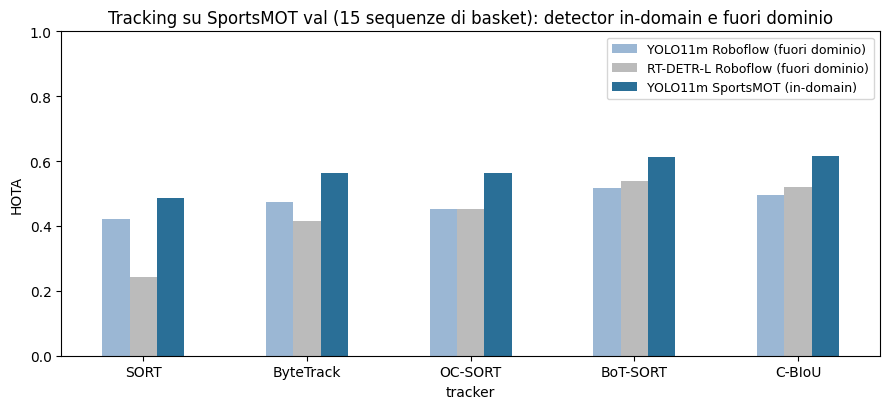

In [9]:
out_dom = pd.read_csv(EXP_E2 / 'results_all_basket.csv').set_index('method')
DETS = {'yolo11m': 'YOLO11m Roboflow (fuori dominio)', 'ft': 'RT-DETR-L Roboflow (fuori dominio)',
        DET_NAME: 'YOLO11m SportsMOT (in-domain)'}
allres = pd.concat([out_dom, res_in])
rows = []
for tr_name in TRACKERS:
    for suffix in ['', '+interp']:
        for key, label in DETS.items():
            m = f'{key}__{tr_name}{suffix}'
            if m in allres.index:
                rows.append({'tracker': tr_name + suffix, 'detector': label, **allres.loc[m, ['HOTA', 'DetA', 'AssA', 'MOTA', 'IDF1', 'IDSW']].to_dict()})
cmp = pd.DataFrame(rows)
cmp.to_csv(EXP / 'confronto_indomain_fuoridominio.csv', index=False)
display(cmp[~cmp.tracker.str.endswith('+interp')].pivot(index='tracker', columns='detector', values='HOTA').round(3))
display(cmp.round(3))

FIG = EXP / 'figures'; FIG.mkdir(exist_ok=True)
pv = cmp[~cmp.tracker.str.endswith('+interp')].pivot(index='tracker', columns='detector', values='HOTA').reindex(TRACKERS)
pv = pv[[l for l in DETS.values() if l in pv.columns]]          # ordine: fuori dominio, poi in-domain
COL = {DETS['yolo11m']: '#9bb7d4', DETS['ft']: '#bbbbbb', DETS[DET_NAME]: '#2a6f97'}
ax = pv.plot.bar(figsize=(9, 4.2), color=[COL[c] for c in pv.columns], rot=0)
ax.set_ylim(0, 1); ax.set_ylabel('HOTA'); ax.set_title('Tracking su SportsMOT val (15 sequenze di basket): detector in-domain e fuori dominio')
ax.legend(fontsize=9); plt.tight_layout(); plt.savefig(FIG / 'hota_indomain_vs_fuoridominio.png', dpi=200); plt.show()

## 9. Registro dell’esperimento (per la tesi e la riproducibilità)

In [10]:
import ultralytics
prov = {
    'data': time.strftime('%Y-%m-%d %H:%M'), 'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'ultralytics': ultralytics.__version__, 'trackers': getattr(T, '__version__', 'n/d'),
    'train_sequenze': [s.name for s in TRAIN_SEQS if s.name not in holdout], 'holdout_sequenze': sorted(holdout),
    'val_sequenze': [s.name for s in VAL_SEQS], 'partite_condivise_train_val': shared,
    'escluse_partite_condivise': EXCLUDE_SHARED_VIDEOS, 'frame_step': FRAME_STEP,
    'immagini_train': tr[0], 'box_train': tr[1], 'immagini_val_interna': va[0], 'box_val_interna': va[1],
    'addestramento': {'pesi_iniziali': BASE_WEIGHTS, 'epoche_max': EPOCHS, 'patience': PATIENCE, 'imgsz': IMGSZ,
                      'batch': BATCH, 'seed': SEED, 'epoche_eseguite': int(len(res)),
                      'epoca_migliore': int(res.loc[res[col].idxmax(), 'epoch']), 'mAP50_95_val_interna': float(res[col].max())},
    'tracking': {'conf_min_detection': DET_CONF_MIN, 'tracker': TRACKERS, 'parametri': 'default della libreria', 'interp_max_gap': INTERP_MAX_GAP},
}
(EXP / 'provenance.json').write_text(json.dumps(prov, indent=2, ensure_ascii=False))
print(json.dumps(prov, indent=2, ensure_ascii=False)[:2500])

{
  "data": "2026-11-07 23:16",
  "gpu": "NVIDIA L4",
  "ultralytics": "8.4.207",
  "trackers": "n/d",
  "train_sequenze": [
    "v_-6Os86HzwCs_c001",
    "v_-6Os86HzwCs_c003",
    "v_-6Os86HzwCs_c007",
    "v_-6Os86HzwCs_c009",
    "v_2j7kLB-vEEk_c001",
    "v_2j7kLB-vEEk_c002",
    "v_2j7kLB-vEEk_c007",
    "v_2j7kLB-vEEk_c009",
    "v_2j7kLB-vEEk_c010",
    "v_4LXTUim5anY_c002",
    "v_4LXTUim5anY_c003",
    "v_4LXTUim5anY_c010",
    "v_4LXTUim5anY_c013"
  ],
  "holdout_sequenze": [
    "v_2j7kLB-vEEk_c005",
    "v_4LXTUim5anY_c012"
  ],
  "val_sequenze": [
    "v_00HRwkvvjtQ_c001",
    "v_00HRwkvvjtQ_c003",
    "v_00HRwkvvjtQ_c005",
    "v_00HRwkvvjtQ_c007",
    "v_00HRwkvvjtQ_c008",
    "v_00HRwkvvjtQ_c011",
    "v_4r8QL_wglzQ_c001",
    "v_5ekaksddqrc_c001",
    "v_5ekaksddqrc_c002",
    "v_5ekaksddqrc_c003",
    "v_5ekaksddqrc_c004",
    "v_5ekaksddqrc_c005",
    "v_BgwzTUxJaeU_c008",
    "v_BgwzTUxJaeU_c012",
    "v_BgwzTUxJaeU_c014"
  ],
  "partite_condivise_train_val": [],
  